# Thành viên 2 Phân đoạn ảnh và tách từng hạt

**Đầu vào:** thư mục `outputs/notebook/01_du_lieu/` do notebook 01 tạo.
Không sử dụng biến từ kernel trước và không import module `.py` của dự án.
Luồng: Otsu → chọn cực tính → Opening/Closing → Connected Components → Watershed khi phù hợp.

In [1]:
from pathlib import Path
from dataclasses import dataclass
from types import SimpleNamespace
import os
import json
import hashlib
import math
import time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from skimage.morphology import h_maxima
from skimage.feature import graycoprops
from IPython.display import display, Markdown

# Mặc định: đặt notebook cạnh raw_dataset và batch_dataset.
# Có thể đổi PROJECT_ROOT sang đường dẫn thư mục dữ liệu của bạn.
PROJECT_ROOT = Path(os.environ.get("RICE_DATA_ROOT", Path.cwd())).resolve()
OUTPUT_ROOT = Path(os.environ.get("RICE_OUTPUT_ROOT", PROJECT_ROOT / "outputs" / "notebook")).resolve()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"

In [2]:
SUPPORTED_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}

def decode_image(data: bytes) -> np.ndarray:
    image = cv2.imdecode(np.frombuffer(data, dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError('Không đọc được ảnh. Hãy dùng ảnh JPG, PNG, BMP hoặc TIFF hợp lệ.')
    return image

def read_image(path) -> np.ndarray:
    return decode_image(Path(path).read_bytes())

def write_image(path, image: np.ndarray) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    ok, encoded = cv2.imencode(path.suffix, image)
    if not ok:
        raise OSError(f'Không mã hóa được ảnh {path}')
    path.write_bytes(encoded.tobytes())

In [3]:
def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def load_stage1():
    folder = OUTPUT_ROOT / "01_du_lieu"
    path = folder / "manifest.csv"
    if not path.is_file():
        raise FileNotFoundError("Chưa có manifest.csv. Hãy chạy notebook 01 trước.")
    frame = pd.read_csv(path, keep_default_na=False)
    valid = frame[(frame["status"] == "ok") & (frame["duplicate_of"] == "")].copy()
    if valid.empty:
        raise ValueError("Không có ảnh hợp lệ duy nhất để xử lý.")
    return frame, valid, file_sha256(path)


def choose_demo(frame):
    matches = frame[frame["image_path"] == "raw_dataset/Tot/picT (1).png"]
    return (matches if len(matches) else frame).iloc[0]


def require_handoff(folder, expected_key, expected_value):
    path = Path(folder) / "handoff.json"
    if not path.is_file():
        raise FileNotFoundError(f"Chưa có {path.name} ở bước trước. Hãy chạy notebook theo thứ tự.")
    info = json.loads(path.read_text(encoding="utf-8"))
    if info.get(expected_key) != expected_value:
        raise ValueError("Dữ liệu bước trước đã thay đổi. Hãy chạy lại các notebook phía sau theo thứ tự.")
    return info

## Cấu hình phân đoạn

`MIN_AREA` tính theo pixel ảnh đã resize. Kiểm tra mask trước khi chọn tham số.
Nếu Otsu bỏ sót hạt tối, có thể đặt `THRESHOLD_OVERRIDE` từ 0 đến 255 và chạy lại.
Watershed chỉ hỗ trợ vùng tiếp xúc; không đảm bảo phục hồi hạt bị che khuất.

In [4]:
MIN_AREA = 12
FOREGROUND = "auto"  # auto, bright, dark
OPENING = 1
CLOSING = 1
USE_WATERSHED = True
THRESHOLD_OVERRIDE = None
STAGE1 = OUTPUT_ROOT / "01_du_lieu"
STAGE2 = OUTPUT_ROOT / "02_phan_doan"
STAGE2.mkdir(parents=True, exist_ok=True)
manifest, valid_images, manifest_hash = load_stage1()
print("Số ảnh nhận bàn giao:", len(valid_images))

Số ảnh nhận bàn giao: 67


## Hàm phân đoạn và Watershed

Mỗi vùng được lưu ID, hộp bao, tâm và mask. Điểm mầm Watershed lấy từ cực đại của distance transform,
lọc các mầm quá gần nhau. Bỏ phép tách nếu tạo vùng quá nhỏ.

In [5]:
@dataclass
class GrainRegion:
    grain_id: int
    bbox: tuple
    mask: np.ndarray
    contour: np.ndarray
    centroid: tuple
    touches_border: bool
    was_split: bool = False

@dataclass
class SegmentationResult:
    binary: np.ndarray
    labels: np.ndarray
    regions: list
    threshold: float
    foreground: str
    warnings: list

def _split_component(mask, min_area):
    """Use separated distance maxima as seeds; avoid splitting a thin grain into many pieces."""
    distance = cv2.distanceTransform(mask.astype(np.uint8), cv2.DIST_L2, 5)
    smooth = cv2.GaussianBlur(distance, (5, 5), 0)
    height = max(1.0, float(distance.max()) * 0.22)
    maxima = h_maxima(smooth, height) & mask
    count, seeds = cv2.connectedComponents(maxima.astype(np.uint8))
    if count <= 2:
        return [mask]
    centers = []
    for seed_id in range(1, count):
        ys, xs = np.where(seeds == seed_id)
        best = np.argmax(smooth[ys, xs])
        centers.append((float(smooth[ys[best], xs[best]]), int(ys[best]), int(xs[best])))
    chosen = []
    for peak, y, x in sorted(centers, reverse=True):
        if all(np.hypot(y - yy, x - xx) >= max(3, min(peak, pp) * 1.25) for pp, yy, xx in chosen):
            chosen.append((peak, y, x))
    if len(chosen) < 2:
        return [mask]
    markers = np.zeros(mask.shape, np.int32)
    markers[~mask] = 1
    for i, (_, y, x) in enumerate(chosen, 2):
        markers[y, x] = i
    relief = np.uint8(255 - cv2.normalize(smooth, None, 0, 255, cv2.NORM_MINMAX))
    cv2.watershed(cv2.cvtColor(relief, cv2.COLOR_GRAY2BGR), markers)
    valid = (markers > 1) & mask
    if not valid.any():
        return [mask]
    # Assign watershed boundaries/background leakage to the nearest surviving seed region.
    nearest = ndi.distance_transform_edt(~valid, return_distances=False, return_indices=True)
    filled = markers[tuple(nearest)]
    parts = [(filled == i) & mask for i in range(2, len(chosen) + 2)]
    if any(int(p.sum()) < min_area for p in parts):
        return [mask]
    return parts

def segment_grains(gray, min_area=12, foreground='auto', opening=1, closing=1, watershed=True, threshold_override=None):
    if gray.ndim != 2 or gray.dtype != np.uint8:
        raise ValueError('Phân đoạn cần ảnh xám uint8.')
    if min_area < 1 or opening < 0 or closing < 0:
        raise ValueError('Diện tích tối thiểu dương, số lần hình thái học không âm.')
    if foreground not in {'auto', 'bright', 'dark'}:
        raise ValueError('foreground phải là auto, bright hoặc dark.')
    threshold, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if threshold_override is not None:
        if not 0 <= threshold_override <= 255:
            raise ValueError('Ngưỡng thủ công phải nằm trong [0,255].')
        threshold, binary = cv2.threshold(gray, float(threshold_override), 255, cv2.THRESH_BINARY)
    if foreground == 'auto':
        border = np.concatenate((binary[0], binary[-1], binary[:, 0], binary[:, -1]))
        foreground = 'dark' if np.mean(border > 0) > 0.5 else 'bright'
    if foreground == 'dark':
        binary = cv2.bitwise_not(binary)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    if opening:
        binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=opening)
    if closing:
        binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel, iterations=closing)
    # Fill only enclosed holes, retaining the outside boundary.
    binary = ndi.binary_fill_holes(binary > 0).astype(np.uint8) * 255
    n, components, stats, _ = cv2.connectedComponentsWithStats(binary)
    labels = np.zeros(gray.shape, np.int32)
    regions = []
    clean = np.zeros_like(binary)
    for component_id in range(1, n):
        x, y, w, h, area = map(int, stats[component_id])
        if area < min_area:
            continue
        # Padding lets watershed see background even when the bounding box is tight.
        x0, y0 = max(0, x - 2), max(0, y - 2)
        x1, y1 = min(gray.shape[1], x + w + 2), min(gray.shape[0], y + h + 2)
        local = components[y0:y1, x0:x1] == component_id
        contours, _ = cv2.findContours(local.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        contour = max(contours, key=cv2.contourArea)
        hull_area = cv2.contourArea(cv2.convexHull(contour))
        solidity = cv2.contourArea(contour) / hull_area if hull_area else 1.0
        parts = _split_component(local, min_area) if watershed and solidity < 0.97 else [local]
        for part in parts:
            ys, xs = np.where(part)
            px, py = int(xs.min()), int(ys.min())
            pw, ph = int(xs.max() - px + 1), int(ys.max() - py + 1)
            roi = part[py:py+ph, px:px+pw].astype(np.uint8) * 255
            cc, _ = cv2.findContours(roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            contour = max(cc, key=cv2.contourArea)
            gx, gy = x0 + px, y0 + py
            contour = contour + np.array([[[gx, gy]]], np.int32)
            grain_id = len(regions) + 1
            labels[gy:gy+ph, gx:gx+pw][roi > 0] = grain_id
            clean[gy:gy+ph, gx:gx+pw][roi > 0] = 255
            touches = gx == 0 or gy == 0 or gx+pw == gray.shape[1] or gy+ph == gray.shape[0]
            regions.append(GrainRegion(grain_id, (gx, gy, pw, ph), roi, contour,
                                       (float(xs.mean()+x0), float(ys.mean()+y0)), touches, len(parts) > 1))
    warnings = []
    if not regions:
        warnings.append('Không phát hiện vùng hợp lệ; kiểm tra nền, ánh sáng và diện tích tối thiểu.')
    if np.mean(clean > 0) > 0.6:
        warnings.append('Tiền cảnh chiếm hơn 60% ảnh; kiểm tra lựa chọn nền và các hạt chồng lấp.')
    if any(r.was_split for r in regions):
        warnings.append('Có vùng được tách bằng Watershed; cần kiểm tra bằng mắt trước khi gán nhãn chuẩn.')
    return SegmentationResult(clean, labels, regions, float(threshold), foreground, warnings)

## Xử lý và lưu kết quả cho toàn bộ ảnh duy nhất

Bản đồ ID được lưu `.npz` nén. ROI/mask từng hạt có thể khôi phục từ bản đồ ID và hộp bao,
tránh tạo hàng chục nghìn ảnh nhỏ. Chỉ xuất thêm các ảnh ROI minh họa cho một ảnh mẫu.

In [6]:
region_rows, image_rows = [], []
region_columns = ["image_id", "grain_id", "x", "y", "w", "h", "center_x", "center_y", "touches_border", "was_split"]
for i, row in enumerate(valid_images.itertuples(index=False), 1):
    gray = cv2.imdecode(np.frombuffer((STAGE1 / row.gray_path).read_bytes(), np.uint8), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise ValueError(f"Không đọc được ảnh xám {row.image_id}.")
    seg = segment_grains(gray, MIN_AREA, FOREGROUND, OPENING, CLOSING, USE_WATERSHED, THRESHOLD_OVERRIDE)
    target = STAGE2 / "instances" / f"{row.image_id}.npz"
    target.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(target, labels=seg.labels)
    mask_path = STAGE2 / "masks" / f"{row.image_id}.png"
    write_image(mask_path, seg.binary)
    for region in seg.regions:
        x, y, w, h = region.bbox
        region_rows.append(dict(image_id=row.image_id, grain_id=region.grain_id, x=x, y=y, w=w, h=h,
                                center_x=region.centroid[0], center_y=region.centroid[1],
                                touches_border=region.touches_border, was_split=region.was_split))
    image_rows.append(dict(image_id=row.image_id, image_path=row.image_path, split=row.split,
                           detected_regions=len(seg.regions), threshold=seg.threshold, foreground=seg.foreground,
                           instance_path=target.relative_to(STAGE2).as_posix(),
                           mask_path=mask_path.relative_to(STAGE2).as_posix(),
                           warnings="; ".join(seg.warnings)))
    if i % 10 == 0 or i == len(valid_images):
        print(f"Đã phân đoạn {i}/{len(valid_images)} ảnh")
regions = pd.DataFrame(region_rows, columns=region_columns)
segmented_images = pd.DataFrame(image_rows)
regions.to_csv(STAGE2 / "regions.csv", index=False, encoding="utf-8-sig")
segmented_images.to_csv(STAGE2 / "images.csv", index=False, encoding="utf-8-sig")
handoff = dict(stage1_manifest_sha256=manifest_hash, regions_sha256=file_sha256(STAGE2 / "regions.csv"),
               images_sha256=file_sha256(STAGE2 / "images.csv"), images=len(segmented_images), regions=len(regions),
               config=dict(min_area=MIN_AREA, foreground=FOREGROUND, opening=OPENING, closing=CLOSING,
                           watershed=USE_WATERSHED, threshold_override=THRESHOLD_OVERRIDE))
(STAGE2 / "handoff.json").write_text(json.dumps(handoff, ensure_ascii=False, indent=2), encoding="utf-8")
display(segmented_images[["image_path", "detected_regions", "threshold", "foreground"]].head(10))

Đã phân đoạn 10/67 ảnh


Đã phân đoạn 20/67 ảnh


Đã phân đoạn 30/67 ảnh


Đã phân đoạn 40/67 ảnh


Đã phân đoạn 50/67 ảnh


Đã phân đoạn 60/67 ảnh


Đã phân đoạn 67/67 ảnh


,image_path,detected_regions,threshold,foreground
0,batch_dataset/picCacloaigao (1).jpg,191,69.0,bright
1,batch_dataset/picCacloaigao (10).jpg,199,90.0,bright
2,batch_dataset/picCacloaigao (11).jpg,210,59.0,bright
3,batch_dataset/picCacloaigao (12).jpg,204,66.0,bright
4,batch_dataset/picCacloaigao (14).jpg,238,78.0,bright
5,batch_dataset/picCacloaigao (16).jpg,204,74.0,bright
6,batch_dataset/picCacloaigao (17).jpg,221,73.0,bright
7,batch_dataset/picCacloaigao (18).jpg,238,85.0,bright
8,batch_dataset/picCacloaigao (19).jpg,280,50.0,bright
9,batch_dataset/picCacloaigao (2).jpg,228,61.0,bright


## Quan sát mask, đường biên và ID của ảnh mẫu

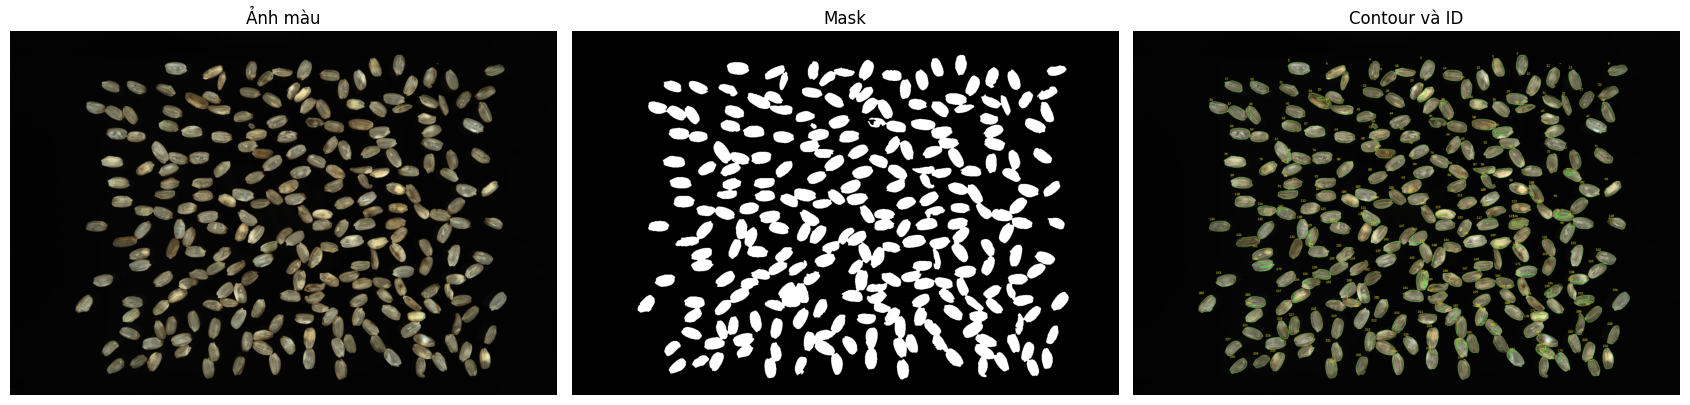

In [7]:
demo = choose_demo(valid_images)
info = segmented_images[segmented_images.image_id == demo.image_id].iloc[0]
color = read_image(STAGE1 / demo.color_path)
with np.load(STAGE2 / info.instance_path, allow_pickle=False) as stored:
    labels = stored["labels"]
overlay = color.copy()
selected_regions = regions[regions.image_id == demo.image_id]
for region in selected_regions.itertuples(index=False):
    x, y, w, h = map(int, (region.x, region.y, region.w, region.h))
    mask = (labels[y:y+h, x:x+w] == region.grain_id).astype(np.uint8) * 255
    cc, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cc = [c + np.array([[[x, y]]], np.int32) for c in cc]
    cv2.drawContours(overlay, cc, -1, (60, 210, 80), 1)
    cv2.putText(overlay, str(region.grain_id), (x, max(10, y-2)), cv2.FONT_HERSHEY_SIMPLEX, .35, (20, 220, 240), 1)
fig, axes = plt.subplots(1, 3, figsize=(17, 7))
for ax, view, title in zip(axes, [cv2.cvtColor(color, cv2.COLOR_BGR2RGB), labels > 0, cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)], ["Ảnh màu", "Mask", "Contour và ID"]):
    ax.imshow(view, cmap="gray" if view.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
write_image(STAGE2 / "sample_annotated.png", overlay)

## Minh họa ROI và mask riêng

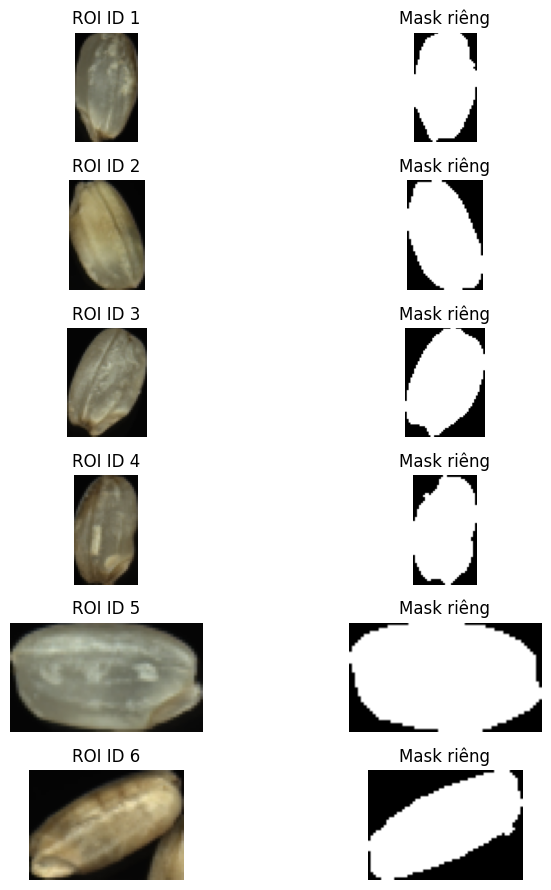

In [8]:
sample_regions = selected_regions.head(6)
if len(sample_regions):
    fig, axes = plt.subplots(len(sample_regions), 2, figsize=(8, max(3, len(sample_regions)*1.5)), squeeze=False)
    for i, region in enumerate(sample_regions.itertuples(index=False)):
        x, y, w, h = map(int, (region.x, region.y, region.w, region.h))
        roi = color[y:y+h, x:x+w]
        mask = (labels[y:y+h, x:x+w] == region.grain_id).astype(np.uint8) * 255
        axes[i, 0].imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
        axes[i, 1].imshow(mask, cmap="gray")
        axes[i, 0].set_title(f"ROI ID {region.grain_id}")
        axes[i, 1].set_title("Mask riêng")
        for ax in axes[i]:
            ax.axis("off")
        write_image(STAGE2 / "sample_rois" / f"{demo.image_id}_{region.grain_id}_color.png", roi)
        write_image(STAGE2 / "sample_rois" / f"{demo.image_id}_{region.grain_id}_mask.png", mask)
    plt.tight_layout()
    plt.show()

## Kiểm tra hành vi và bàn giao

Kiểm thử ảnh tổng hợp chỉ xác nhận hành vi tách vùng, không phải độ chính xác trên ảnh thật.
Sản phẩm cho notebook 03: `regions.csv`, `images.csv`, `instances/`, `masks/`, `handoff.json`.
Hãy kiểm tra mask thực tế, nhất là hạt tối hoặc tiếp xúc, trước khi sử dụng đặc trưng.

In [9]:
touching = np.zeros((160, 200), np.uint8)
cv2.circle(touching, (75, 80), 30, 255, -1)
cv2.circle(touching, (120, 80), 30, 255, -1)
assert len(segment_grains(touching, watershed=False).regions) == 1
assert len(segment_grains(touching, watershed=True).regions) == 2
assert len(segment_grains(np.zeros((100, 100), np.uint8)).regions) == 0
assert int(segmented_images.detected_regions.sum()) == len(regions)
print("Đạt: tách hai vùng tiếp xúc trong ảnh thử; ảnh rỗng không có vùng; tổng ID nhất quán.")

Đạt: tách hai vùng tiếp xúc trong ảnh thử; ảnh rỗng không có vùng; tổng ID nhất quán.
